# A short introduction to containerized software

After spending time using nf-core pipelines to answer bioinformatic questions, we will focus on the processes that lie behind these pipelines now.

Today, we will focus on containerization, namely via Docker. 



1. Check if Docker is installed.

In [2]:
import os
os.environ["PATH"] += os.pathsep + "/Applications/Docker.app/Contents/Resources/bin"
!docker ps

CONTAINER ID   IMAGE     COMMAND   CREATED   STATUS    PORTS     NAMES


In [4]:
!docker info

Client:
 Version:    29.8.0
 Context:    desktop-linux
 Debug Mode: false
 Plugins:
  agent: Docker AI Agent Runner (Docker Inc.)
    Version:  v1.140.0
    Path:     /Users/km/.docker/cli-plugins/docker-agent
  ai: Docker AI Agent - Ask Gordon (Docker Inc.)
    Version:  v1.31.0
    Path:     /Users/km/.docker/cli-plugins/docker-ai
  buildx: Docker Buildx (Docker Inc.)
    Version:  v0.37.1
    Path:     /Users/km/.docker/cli-plugins/docker-buildx
  compose: Docker Compose (Docker Inc.)
    Version:  v5.5.1
    Path:     /Users/km/.docker/cli-plugins/docker-compose
  debug: Get a shell into any image or container (Docker Inc.)
    Version:  0.0.47
    Path:     /Users/km/.docker/cli-plugins/docker-debug
  desktop: Docker Desktop commands (Docker Inc.)
    Version:  v0.4.4
    Path:     /Users/km/.docker/cli-plugins/docker-desktop
  dhi: CLI for managing Docker Hardened Images (Docker Inc.)
    Version:  v0.0.7
    Path:     /Users/km/.docker/cli-plugins/docker-dhi
  extension: Manages

### What is a container?

A container is a self-contained package that holds a piece of software together with everything it needs to run: the right versions of libraries, dependencies, system tools, and settings. You run it with a container engine like Docker or Singularity/Apptainer, and it behaves the same on any machine.

### Why do we use containers?

Docker streamlines the development lifecycle by allowing developers to work in standardized environments using local containers which provide your applications and services. Containers are great for continuous integration and continuous delivery (CI/CD) workflows.

### What is a docker image?

An image is the read-only template or blueprint, standalone and executable software package that includes everything needed to run an application: the code, a runtime, system tools, libraries and settings. A container is a running instance of that image. The engine is the program that runs images: Docker, Singularity/Apptainer, or Podman.

### Let's run our first docker image:

### Login to docker

In [ ]:
# This you need to do on the command line directly

### Run your first docker container

In [5]:
!docker run hello-world

Unable to find image 'hello-world:latest' locally
latest: Pulling from library/hello-world

e6a49ef1: Pull complete ete [1A
Digest: sha256:5e23090353324d887c48ad5e5c56d294eab81588df9605b07d1afe895f9cc8f8
Status: Downloaded newer image for hello-world:latest

Hello from Docker!
This message shows that your installation appears to be working correctly.

To generate this message, Docker took the following steps:
 1. The Docker client contacted the Docker daemon.
 2. The Docker daemon pulled the "hello-world" image from the Docker Hub.
    (arm64v8)
 3. The Docker daemon created a new container from that image which runs the
    executable that produces the output you are currently reading.
 4. The Docker daemon streamed that output to the Docker client, which sent it
    to your terminal.

To try something more ambitious, you can run an Ubuntu container with:
 $ docker run -it ubuntu bash

Share images, automate workflows, and more with a free Docker ID:
 https://hub.docker.com/

For more

### Find the container ID

In [ ]:
0a699a023a18

### Delete the container again, give prove its deleted

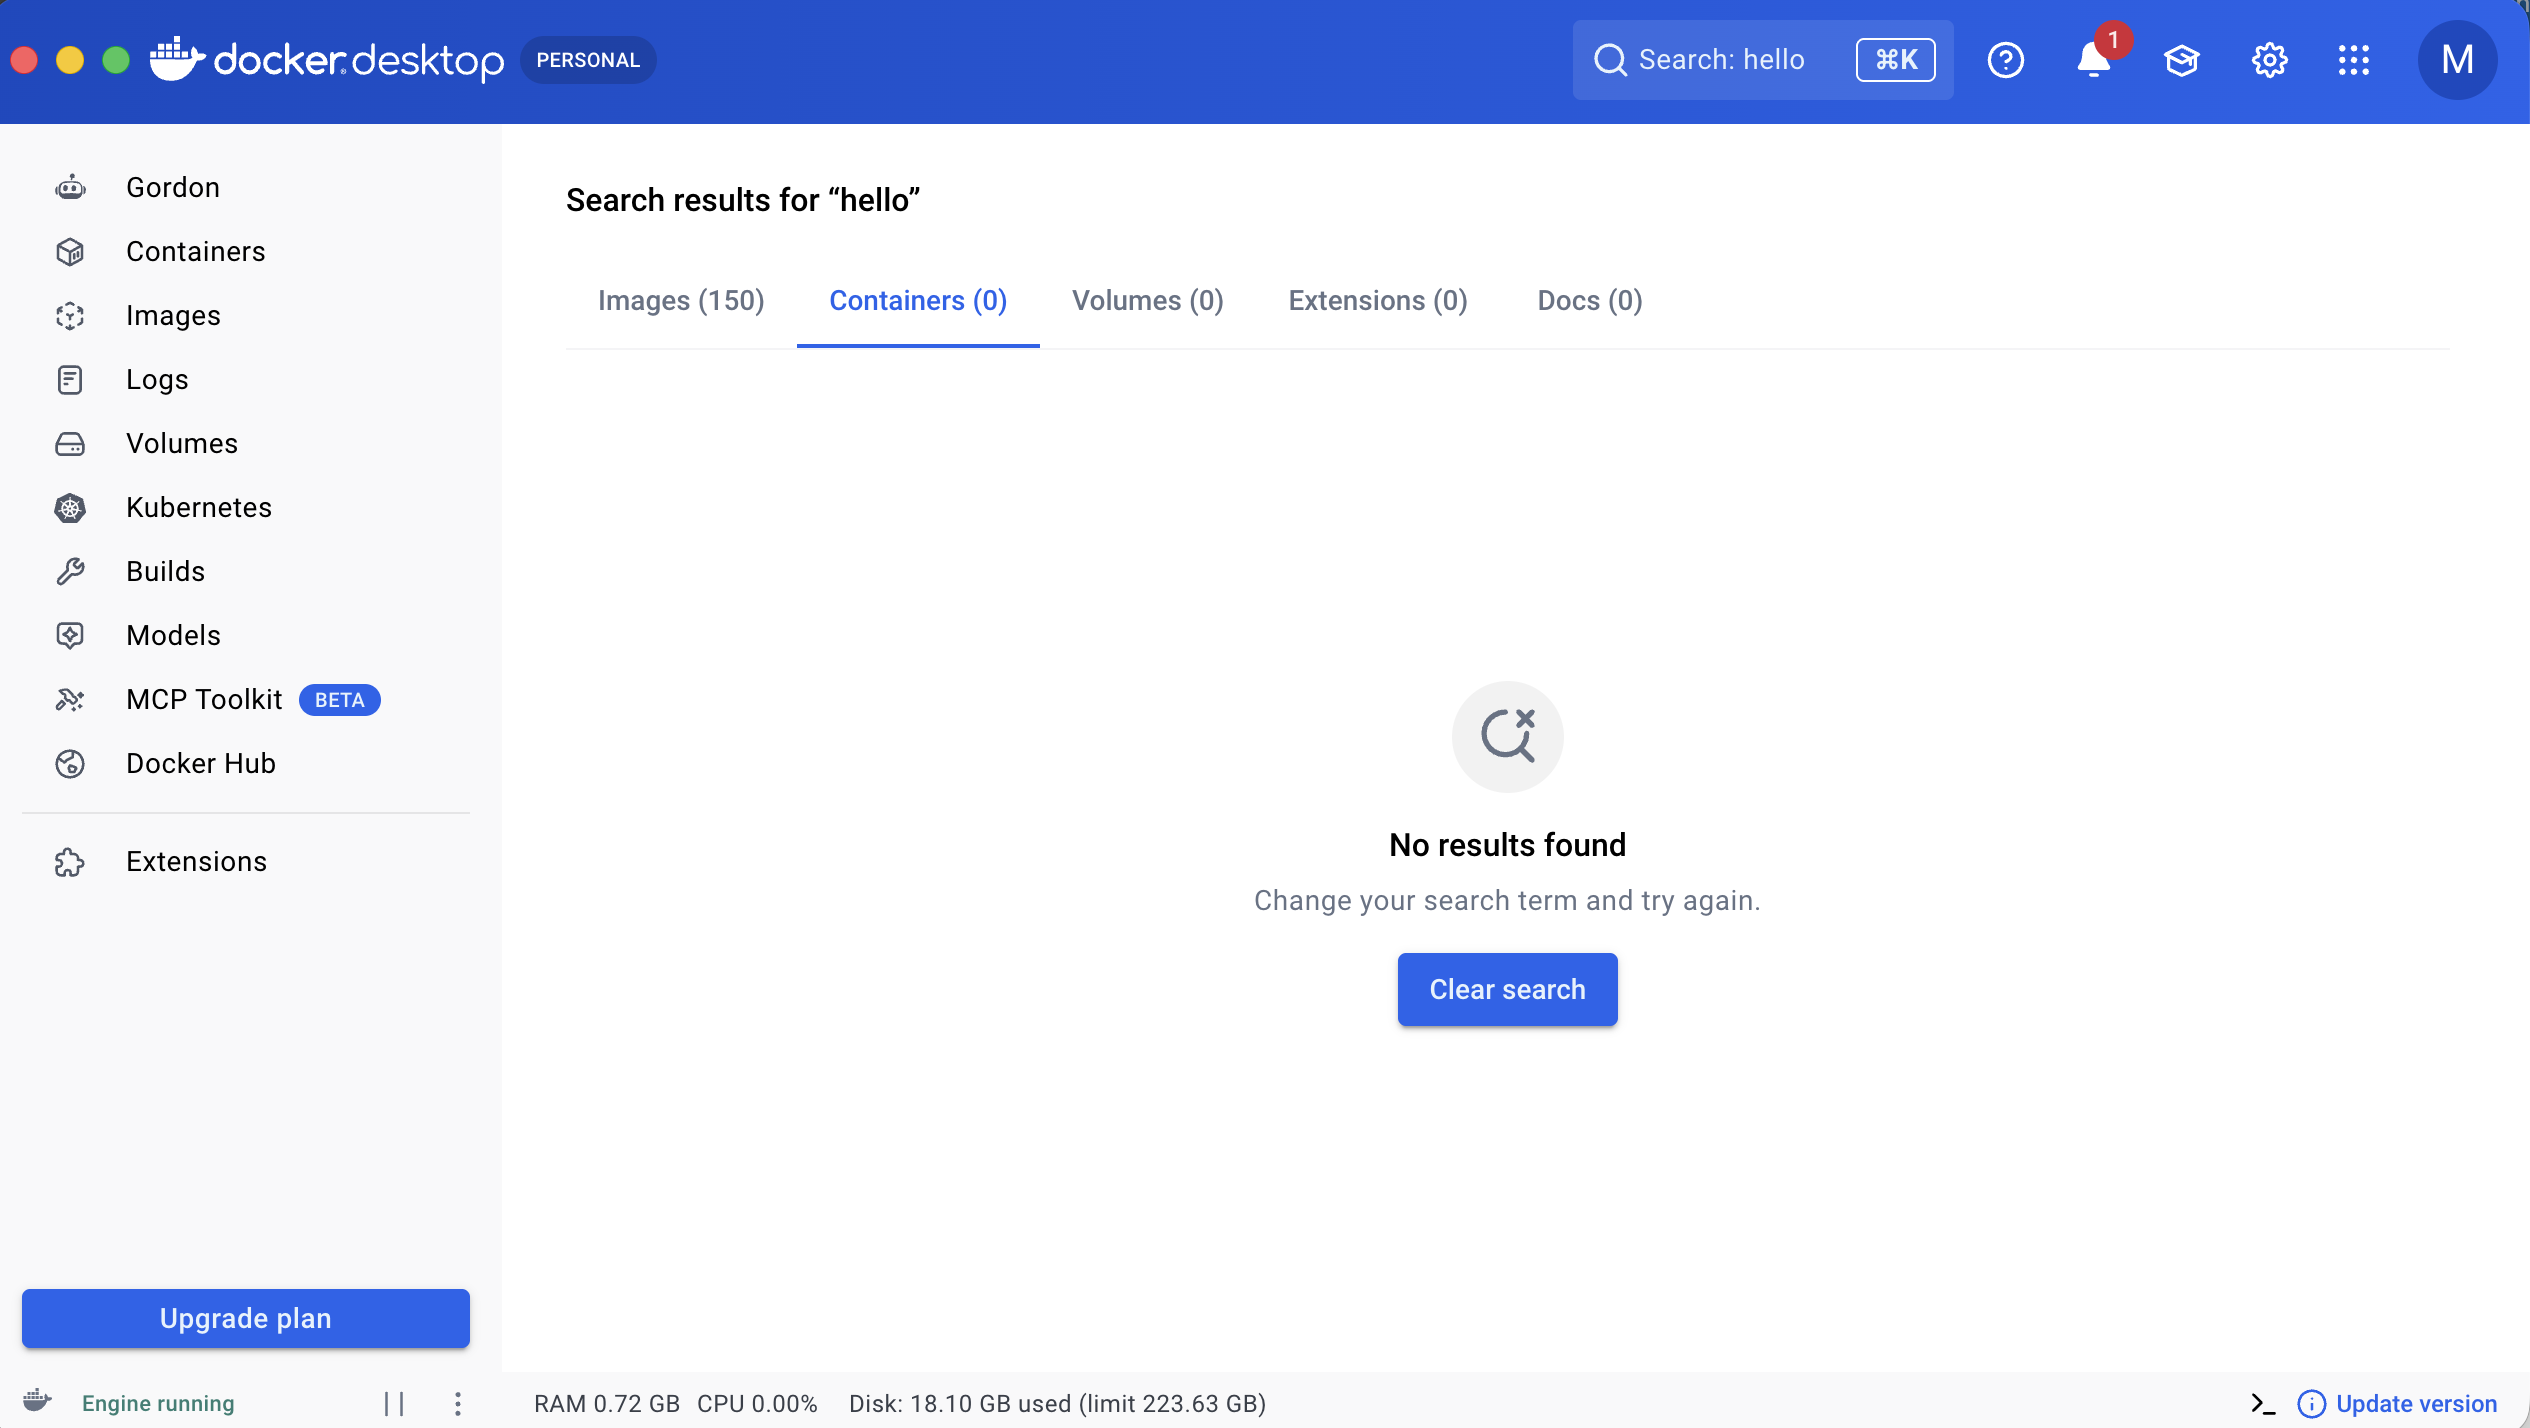

In [6]:
from IPython.display import Image, display

display(Image(filename="deleted_image.png"))

### FASTQC is a very useful tool as you've learned last week. Let's try and run it from command line

Link to the software: https://www.bioinformatics.babraham.ac.uk/projects/fastqc/

Please describe the steps you took to download and run the software for the example fastq file from last week below:

1. I already had fastqc installed ; mkdir -p fastqc_results
2. fastqc day_02/fetchngs_out/fastq/SRX19144486_SRR23195516_1.fastq.gz -o fastqc_results

### Very well, now let's try to make use of its docker container

1. create a container holding fastqc using seqera containers (https://seqera.io/containers/)
2. use the container to generate a fastqc html of the example fastq file

In [ ]:
# pull the container
!docker pull community.wave.seqera.io/library/fastqc:0.12.1--1707b8e896a1f483

In [8]:
# run the container and save the results to a new "fastqc_results" directory
!docker run --rm -v /Users/km/Documents/GitHub/computational-workflows-2026:/data -w /data community.wave.seqera.io/library/fastqc:0.12.1--1707b8e896a1f483 fastqc day_02/fetchngs_out/fastq/SRX19144486_SRR23195516_2.fastq.gz -o 

Option outdir requires an argument
application/gzip
Started analysis of SRX19144486_SRR23195516_2.fastq.gz
Approx 5% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 10% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 15% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 20% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 25% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 30% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 35% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 40% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 45% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 50% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 55% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 60% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 65% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 70% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 75% complete for SRX19144486_SRR23195516_2.fastq.gz
Approx 80

### Now that you know how to use a docker container, which approach was easier and which approach will be easier in the future?

the manual install is about as fast for one tool.
In future: Docker is easier. There’s nothing to install, no Java or dependency issues, it’s the same on every computer, and switching tools or versions means changing one line.

### What would you say, which approach is more reproducible?

Docker. The image fixes the tool version and all its dependencies and the operating system, so anyone running the same image gets the same environment. A manual install depends on your machine’s Java and libraries.

### Compare the file to last weeks fastqc results, are they identical?
### Is the fastqc version identical?

yes, identical

## Dockerfiles

We now used Docker containers and images directly to boost our research. 

Let's create our own toy Dockerfile including the "cowsay" tool (https://en.wikipedia.org/wiki/Cowsay)

Hints:
1. Docker is Linux, so you need to know the apt-get command to install "cowsay"

In [11]:
# open the file "my_dockerfile" in a text editor

### Explain the RUN and ENV lines you added to the file

This RUN chains three commands.

apt-get update downloads Debian's current list of available packages. The debian:bookworm-slim base image ships without this list to save space, so without this step apt-get wouldn't know where to find curl or cowsay.

apt-get install -y curl cowsay downloads and installs both programs, along with anything they depend on. apt-get is Debian's package manager, its equivalent of pip or conda. The -y automatically answers "yes" to the confirmation prompt. Nobody can type during a build, so without it the build would stop and fail.

rm -rf /var/lib/apt/lists/* deletes the package list from the first step. It was only needed for installing, so removing it keeps the image smaller.

&& runs the next command only if the previous one succeeded, so if the update fails, Docker doesn't try to install. \ continues the command on the next line, so these three lines are one instruction.

ENV sets an environment variable that is stored in the image and present in every container started from it.
"$PATH:/usr/games" takes the existing PATH ($PATH) and adds /usr/games to the end. It's important to keep $PATH: writing only PATH="/usr/games" would replace the whole list, and the shell would no longer find basic commands like ls or curl in /usr/bin and /bin.

In [17]:
# build the docker image

!docker build -t my_cowsay -f /Users/km/Documents/GitHub/computational-workflows-2026/day_04/my_dockerfile /Users/km/Documents/GitHub/computational-workflows-2026/day_04

[+] Building 0.0s (0/1)                                    docker:desktop-linux
 => [internal] load build definition from my_dockerfile                    0.0s
[+] Building 0.2s (2/3)                                    docker:desktop-linux
 => [internal] load build definition from my_dockerfile                    0.0s
 => => transferring dockerfile: 987B                                       0.0s
 => [internal] load metadata for docker.io/library/debian:bookworm-slim    0.2s
 => [auth] library/debian:pull token for registry-1.docker.io              0.0s
[+] Building 0.4s (2/3)                                    docker:desktop-linux
 => [internal] load build definition from my_dockerfile                    0.0s
 => => transferring dockerfile: 987B                                       0.0s
 => [internal] load metadata for docker.io/library/debian:bookworm-slim    0.4s
 => [auth] library/debian:pull token for registry-1.docker.io              0.0s
[+] Building 0.5s (2/3)                 

In [18]:
# make sure that the image has been built
!docker images my_cowsay

                                                            i Info →   U  In Use
IMAGE              ID             DISK USAGE   CONTENT SIZE   EXTRA
my_cowsay:latest   c275f7ff50ba        226MB         45.4MB        


In [21]:
# run the docker file 
!docker run --rm my_cowsay cowsay "always spread love"

 ____________________
< always spread love >
 --------------------
        \   ^__^
         \  (oo)\_______
            (__)\       )\/\
                ||----w |
                ||     ||


## Let's do some bioinformatics with the docker file and create a new docker file that holds the salmon tool used in rnaseq

To do so, use "curl" in your new dockerfile to get salmon from https://github.com/COMBINE-lab/salmon/releases/download/v1.5.2/salmon-1.5.2_linux_x86_64.tar.gz

In [ ]:
# use the file "salmon_docker" in this directory to build a new docker image

In [3]:
# build the image
!docker build --progress=plain --platform linux/amd64 -t my_salmon -f /Users/km/Documents/GitHub/computational-workflows-2026/day_04/salmon_dockerfile /Users/km/Documents/GitHub/computational-workflows-2026/day_04

#0 building with "desktop-linux" instance using docker driver

#1 [internal] load build definition from salmon_dockerfile
#1 transferring dockerfile: 698B done
#1 WARN: FromPlatformFlagConstDisallowed: FROM --platform flag should not use constant value "linux/amd64" (line 1)
#1 DONE 0.0s

#2 [auth] library/debian:pull token for registry-1.docker.io
#2 DONE 0.0s

#3 [internal] load metadata for docker.io/library/debian:bookworm-slim
#3 DONE 0.8s

#4 [internal] load .dockerignore
#4 transferring context: 2B done
#4 DONE 0.0s

#5 [1/3] FROM docker.io/library/debian:bookworm-slim@sha256:3783cc01769c7b2b1b83a5c5ad96c815348e28ed7da68e2e3687004faa906251
#5 resolve docker.io/library/debian:bookworm-slim@sha256:3783cc01769c7b2b1b83a5c5ad96c815348e28ed7da68e2e3687004faa906251 done
#5 sha256:774043ccc8ccd0d0833a9ee0792142ab7ad93df971e59dd248fbf82db16d0150 0B / 28.24MB 0.2s
#5 sha256:774043ccc8ccd0d0833a9ee0792142ab7ad93df971e59dd248fbf82db16d0150 7.34MB / 28.24MB 1.2s
#5 sha256:774043ccc8ccd0d083

In [7]:
# run the docker image to give out the version of salmon
!docker run --rm --platform linux/amd64 my_salmon salmon --version

salmon 1.5.2


## Do you think bioinformaticians have to create a docker image every time they want to run a tool?

No, Ready-made images exist for almost every bioinformatics tool (BioContainers, Seqera Containers), and nf-core modules bring their own. You only write a Dockerfile for custom combinations or tools without an image.

Find the salmon docker image online and run it on your computer.

What is https://biocontainers.pro/ ?

A community-driven project to create and manage scientific software containers

## Are there other ways to create Docker (or Apptainer) images?

-Writing a Dockerfile, or an Apptainer definition file (.def).
-Converting a Docker image with apptainer build image.sif docker://....
-Building from conda environments, e.g. Seqera Containers / Wave or micromamba-based images.
-Using existing BioContainers images.

What is https://seqera.io/containers/ ?

A free service from Seqera that builds Docker or Singularity images on demand from any combination of Conda (Bioconda/conda-forge) or PyPI packages. You choose the packages, it returns a public image address, and it can build for amd64 or arm64. nf-core modules use these images.